# Embedding Models
We have yet to take a deeper look at the tweets in specific. Unlike categorical or numeric data, tweets are natural language. They require special attention, as we can not average them, and they are far too unique to consider each its own category.

In [6]:
import kagglehub
import pandas as pd
import numpy as numpy
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from sklearn.feature_extraction.text import CountVectorizer

In [2]:
dataset_path = 'goyaladi/twitter-bot-detection-dataset'

local_path = kagglehub.dataset_download("goyaladi/twitter-bot-detection-dataset")
df = pd.read_csv(local_path + "/bot_detection_data.csv")

In [4]:
df['Tweet'].values

<StringArray>
[          'Station activity person against natural majority none few size expect six marriage.',
                 'Authority research natural life material staff rate common protect attention.',
                                 'Manage whose quickly especially foot none to goal range case.',
                                             'Just cover eight opportunity strong policy which.',
                                                                 'Animal sign six data good or.',
                                 'See wonder travel this suffer less yard office man certainly.',
                                                      'Door final sound my guess building rich.',
                                              'Job phone price magazine worry stage check view.',
                                                            'Eye rest prove mission show floor.',
                      'Add letter year performance western what culture large development fast.',
 ...
 

## Strategy 1, Bag of Words

We count how many time a particular top k word appeared in a sentence and use that to make a k length vector. We do this for all sentence so we have a fixed length representation. 

In [20]:
total_unqiue_words = set([word for tweet in df['Tweet'].values for word in tweet.split(' ')])
len(total_unqiue_words), list(total_unqiue_words)[:10]

(2906,
 ['market',
  'almost',
  'before',
  'develop',
  'southern',
  'trial.',
  'man',
  'Decade',
  'Trip',
  'kid.'])

In [13]:
vectorizer = CountVectorizer(max_features=500, stop_words='english')
X = vectorizer.fit_transform(df['Tweet'].values)

In [14]:
vectorizer.get_feature_names_out()

array(['ability', 'accept', 'account', 'action', 'activity', 'address',
       'administration', 'admit', 'adult', 'age', 'agent', 'ago', 'agree',
       'ahead', 'american', 'analysis', 'animal', 'answer', 'apply',
       'area', 'argue', 'arm', 'arrive', 'art', 'article', 'artist',
       'ask', 'assume', 'attack', 'audience', 'author', 'authority',
       'available', 'avoid', 'away', 'baby', 'ball', 'bank', 'bar',
       'beat', 'beautiful', 'begin', 'behavior', 'benefit', 'best', 'big',
       'black', 'blue', 'board', 'body', 'born', 'boy', 'bring', 'budget',
       'building', 'camera', 'campaign', 'candidate', 'capital', 'car',
       'career', 'carry', 'case', 'cause', 'cell', 'center', 'central',
       'certain', 'chair', 'challenge', 'chance', 'charge', 'child',
       'choose', 'church', 'citizen', 'claim', 'clear', 'clearly', 'cold',
       'collection', 'college', 'commercial', 'common', 'community',
       'computer', 'concern', 'condition', 'conference', 'congress',
  

In [22]:
X.toarray().shape

(50000, 500)

In [23]:
np.linalg.cond(X.toarray())

np.float64(2.6859562585658123)

### Result of BOW
Very nice we have a low condition number. It also makes sense, by having a combination of words you cant grantee that another specific word is present. It might be possible for a few words like a noun and the article "Thea" or "a" however there are many nouns in our tweets so it appears to not have a significant impact. 

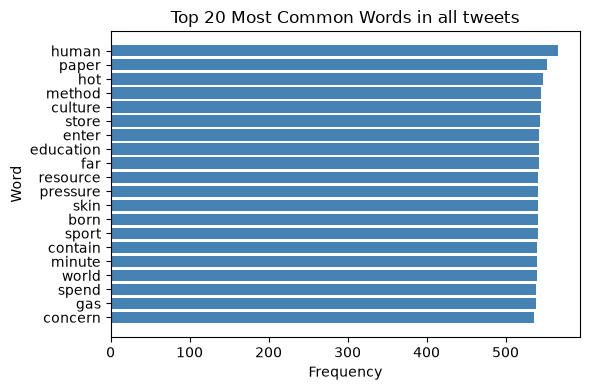

In [28]:
word_counts = X.sum(axis=0).A1

# Build frequency dataframe
word_freq = pd.DataFrame({
    'Word': vectorizer.get_feature_names_out(),
    'Frequency': word_counts
}).sort_values('Frequency', ascending=False)

# Display only top 20
top_words = word_freq.head(20)

# Plot
plt.figure(figsize=(6, 4))
plt.barh(top_words['Word'], top_words['Frequency'], color='steelblue')

plt.xlabel('Frequency')
plt.ylabel('Word')
plt.title('Top 20 Most Common Words in all tweets')
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

### Side by side comparison of top 20 words in bot and non bot tweets.  

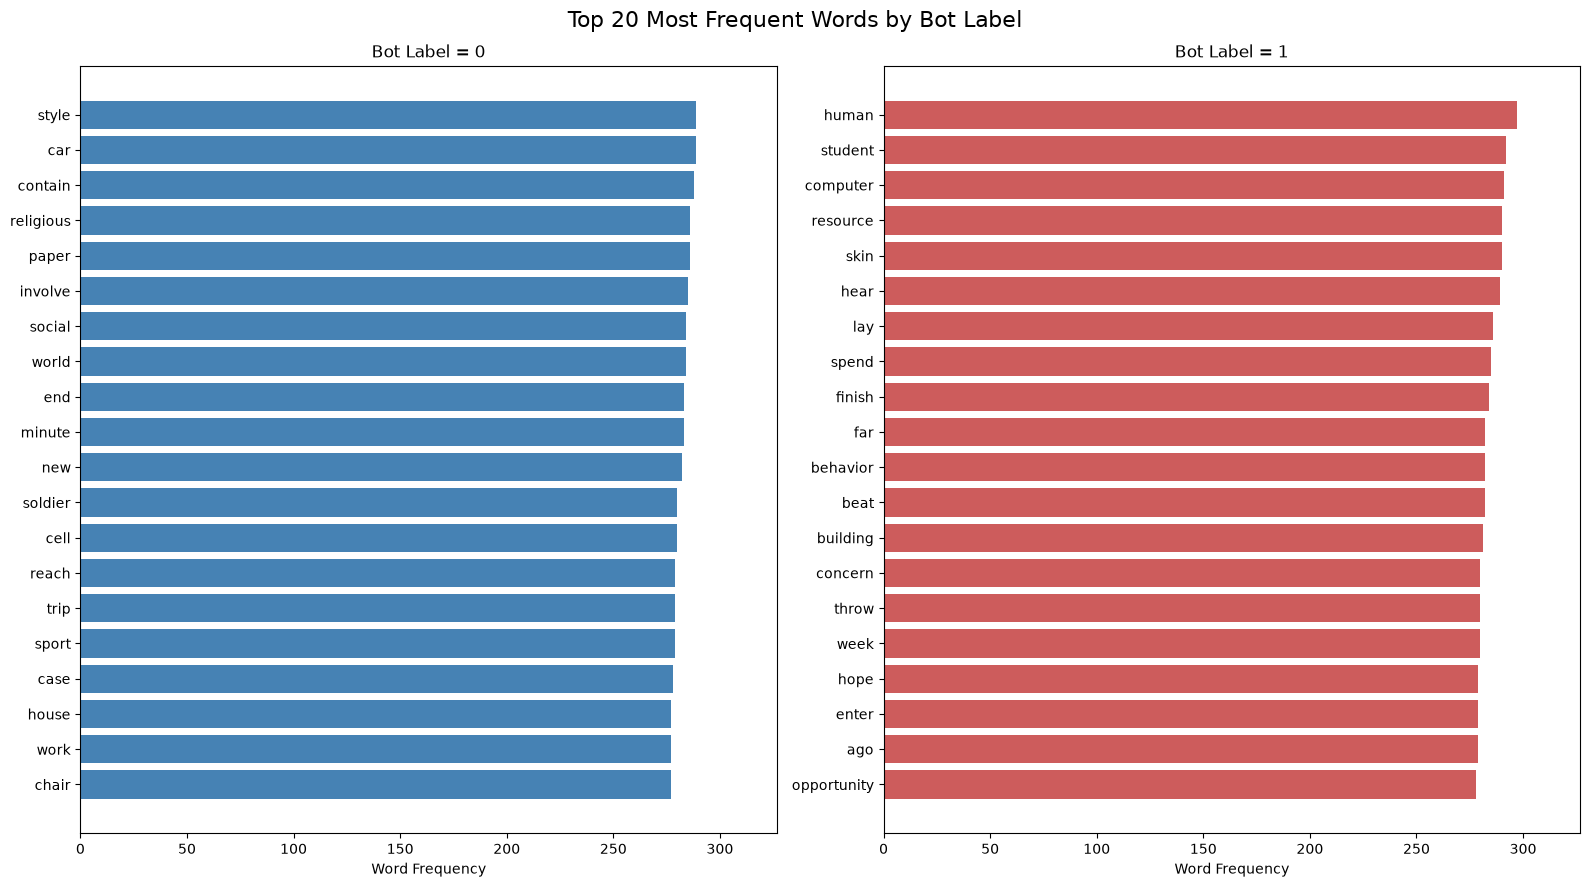

In [31]:
TOP_N = 20
MAX_FEATURES = 1000

# Separate tweets by class
tweets_0 = df.loc[df['Bot Label'] == 0, 'Tweet'].dropna().astype(str)
tweets_1 = df.loc[df['Bot Label'] == 1, 'Tweet'].dropna().astype(str)


def get_top_words(tweets, max_features=1000, top_n=20):
    vectorizer = CountVectorizer(
        stop_words='english',
        max_features=max_features
    )

    X = vectorizer.fit_transform(tweets)

    word_counts = X.sum(axis=0).A1

    word_freq = pd.DataFrame({
        'Word': vectorizer.get_feature_names_out(),
        'Frequency': word_counts
    })

    return word_freq.sort_values(
        'Frequency', ascending=False
    ).head(top_n)


# Get top words for each class
top_0 = get_top_words(tweets_0, MAX_FEATURES, TOP_N)
top_1 = get_top_words(tweets_1, MAX_FEATURES, TOP_N)

# Shared x-axis scale for comparison
max_freq = max(
    top_0['Frequency'].max(),
    top_1['Frequency'].max()
)

# Plot side by side
fig, axes = plt.subplots(1, 2, figsize=(16, 9))

# Class 0
axes[0].barh(
    top_0['Word'],
    top_0['Frequency'],
    color='steelblue'
)
axes[0].set_title('Bot Label = 0')
axes[0].set_xlabel('Word Frequency')
axes[0].set_xlim(0, max_freq * 1.1)
axes[0].invert_yaxis()

# Class 1
axes[1].barh(
    top_1['Word'],
    top_1['Frequency'],
    color='indianred'
)
axes[1].set_title('Bot Label = 1')
axes[1].set_xlabel('Word Frequency')
axes[1].set_xlim(0, max_freq * 1.1)
axes[1].invert_yaxis()

fig.suptitle('Top 20 Most Frequent Words by Bot Label', fontsize=16)
plt.tight_layout()
plt.show()